# AI Detector Bias: An Exploratory Evaluation of GPTZero 5.0b

**Author:** Yeju Seol  
**Course:** DS480: Data, Society, and AI Ethics

## Study Overview

This study evaluates whether GPTZero 5.0b falsely classifies
human-written essays as AI-generated. I used 30 TOEFL essays and 30 US student essays drawn from the public dataset
released by Liang et al. (2023) for the evaluation.

The primary outcome is the AI-only false-positive rate, based on the detector's final document-level classification. Mixed and AI-edited classifications are reported separately.

Only human-written texts are evaluated. Thus, the outcomes in this project cannot identify how good GPTZero can identify AI-generated writings.

The scans were done manually through GPTZero website (https://gptzero.me/). Running this notebook will load the recorded results and their analysis.

## 1. Environment and Required Files

Code cells must be ran in order.

The project directory must contain:

- `data/corpus.csv`
- `data/evaluation_selection_60.csv`
- `results/manual_results.csv`
- `results/screenshots/`

`corpus.csv` contains the original texts and their matched historical scores.
`evaluation_selection_60.csv` preserves the evaluated sample.
`manual_results.csv` contains the recorded web-scan results from GPTZero.

In Google Colab, set `USE_DRIVE = True` to access the existing project
directory in Google Drive.

In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

USE_DRIVE = True

if USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    ROOT = Path(
        "/content/drive/MyDrive/DS480_AI_Detector"
    )
else:
    ROOT = Path.cwd()

RESULTS_PATH = ROOT / "results" / "manual_results.csv"
SELECTION_PATH = (
    ROOT / "data" / "evaluation_selection_60.csv"
)

required_files = [
    ROOT / "data" / "corpus.csv",
    SELECTION_PATH,
    RESULTS_PATH,
]

missing_files = [
    str(path)
    for path in required_files
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Required files are missing:\n"
        + "\n".join(missing_files)
    )

print("Required input files found.")

Mounted at /content/drive
Required input files found.


## 2. Data Sources and Sample Selection

The source corpus contains 91 human-written TOEFL essays and
88 human-written US student essays from the dataset released by Liang et al. (2023).

Here, the original texts were preserved without spelling or grammar corrections.

An initial pilot selected 10 essays per group using Python's
`random.Random(480)`. After reviewing the pilot results, the evaluation was expanded by 20 essays per group using `random.Random(48040)`.
Additional sampling excluded texts that are already represented in the pilot and duplicate texts within each group's candidate pool.

The final sample contains 30 essays per group. The saved selection file is used for analysis and doesn't draw a new sample.

In [2]:
corpus = pd.read_csv(
    ROOT / "data" / "corpus.csv",
    keep_default_na=False,
)

selection = pd.read_csv(
    SELECTION_PATH,
    dtype=str,
    keep_default_na=False,
)

saved_results = pd.read_csv(
    RESULTS_PATH,
    dtype=str,
    keep_default_na=False,
)

if not corpus["essay_id"].is_unique:
    raise ValueError("Duplicate IDs in the source corpus.")

if not selection["essay_id"].is_unique:
    raise ValueError("Duplicate IDs in the saved selection.")

if not saved_results["essay_id"].is_unique:
    raise ValueError("Duplicate IDs in the manual results.")

if not set(selection["essay_id"]).issubset(
    set(corpus["essay_id"])
):
    raise ValueError("Selected IDs are missing from the corpus.")

selected_corpus = selection[
    ["essay_id", "group"]
].merge(
    corpus[["essay_id", "group", "text", "word_count"]],
    on="essay_id",
    how="left",
    suffixes=("_selection", "_corpus"),
    validate="one_to_one",
)

if not selected_corpus["group_selection"].eq(
    selected_corpus["group_corpus"]
).all():
    raise ValueError("Group labels do not match the corpus.")

if selected_corpus.duplicated(
    ["group_selection", "text"]
).any():
    raise ValueError("Duplicate texts within selected groups.")

expected_counts = {
    "TOEFL": 30,
    "US_student": 30,
}

if selection.groupby("group").size().to_dict() != expected_counts:
    raise ValueError("Expected 30 selected essays per group.")

print("Selected sample:")
display(
    selection.groupby(["group", "stage"])
    .size()
    .unstack(fill_value=0)
)

print("Source corpus size:", len(corpus))
print("Selected sample size:", len(selection))

Selected sample:


stage,additional,original_pilot
group,,
TOEFL,20,10
US_student,20,10


Source corpus size: 179
Selected sample size: 60


## 3. Manual Evaluation

Each essay was scanned separately with GPTZero without any revision. Screenshots were taken for each essay as evidence for the displayed record.

Labels follow the final verdict, although it shows mixed probability of 1% (ex.TOEFL_072).

## 4. Check the Records

The following code identifies missing records, duplicate texts, model versions,
and missing screenshots.

In [3]:
selection = pd.read_csv(
    ROOT / "data" / "evaluation_selection_60.csv",
    dtype=str,
    keep_default_na=False,
)

saved_results = pd.read_csv(
    ROOT / "results" / "manual_results.csv",
    dtype=str,
    keep_default_na=False,
)

for name, table in [
    ("selection", selection),
    ("results", saved_results),
    ("corpus", corpus),
]:
    if not table["essay_id"].is_unique:
        raise ValueError(f"Duplicate essay IDs in {name}.")

# Check group labels against the original corpus.
group_check = selection.merge(
    corpus[["essay_id", "group"]],
    on="essay_id",
    how="left",
    suffixes=("_selection", "_corpus"),
    validate="one_to_one",
)

if not group_check["group_selection"].eq(
    group_check["group_corpus"]
).all():
    raise ValueError("Selected groups do not match the corpus.")

analysis_data = selection.merge(
    saved_results,
    on="essay_id",
    how="left",
    validate="one_to_one",
).merge(
    corpus[["essay_id", "text", "word_count"]],
    on="essay_id",
    how="left",
    validate="one_to_one",
)

expected_counts = {"TOEFL": 30, "US_student": 30}

if analysis_data.groupby("group").size().to_dict() != expected_counts:
    raise ValueError("Expected 30 essays per group.")

if not analysis_data["status"].eq("scanned").all():
    raise ValueError("Some selected essays are not scanned.")

if not analysis_data["label"].isin(
    ["Human", "AI", "Mixed", "AI-edited"]
).all():
    raise ValueError("Some labels need review.")

if analysis_data["text"].isna().any():
    raise ValueError("Some original texts are missing.")

if analysis_data.duplicated(["group", "text"]).any():
    raise ValueError("Duplicate texts found within groups.")

analysis_data["word_count"] = pd.to_numeric(
    analysis_data["word_count"],
    errors="raise",
)

missing_evidence = []

for row in analysis_data.itertuples():
    filename = str(row.evidence_file).strip()

    if not filename or not (
        ROOT / "results" / filename
    ).is_file():
        missing_evidence.append(row.essay_id)

print("Recorded labels:")
display(
    pd.crosstab(
        analysis_data["group"],
        analysis_data["label"],
    )
)

print("Missing evidence files:", missing_evidence)

print("\nModel versions:")
display(analysis_data["model_version"].value_counts())

if not analysis_data["model_version"].eq("5.0b").all():
    raise ValueError("Model versions differ; review before pooling.")

Recorded labels:


label,Human
group,
TOEFL,30
US_student,30


Missing evidence files: []

Model versions:


,count
model_version,
5.0b,60


## 5. False-Positive Rates

A false positive means that human writing was labeled as AI-generated. The table and figure below show each group's error rate and 95% Wilson
confidence interval. Mixed and AI-edited verdicts are counted separately.

,group,evaluated_n,AI_false_positives,FPR_percent,CI_95_lower_percent,CI_95_upper_percent,Mixed_or_AI_edited_n
0,TOEFL,30,0,0.0,0.0,11.35,0
1,US_student,30,0,0.0,0.0,11.35,0


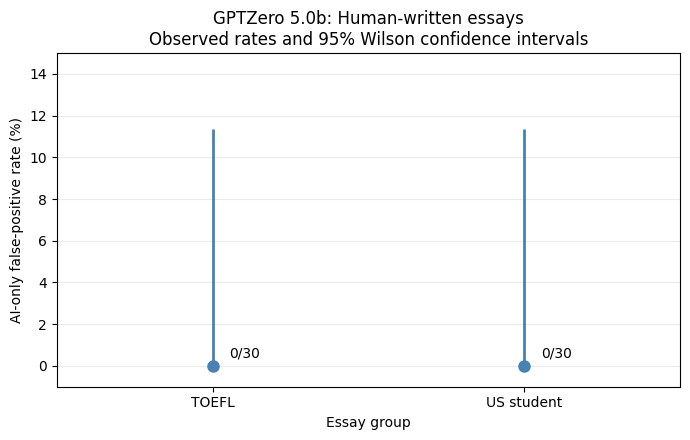

In [4]:
import math
import matplotlib.pyplot as plt


def wilson_interval(k, n):
    if n == 0:
        return float("nan"), float("nan")

    z = 1.959963984540054
    p = k / n
    denominator = 1 + z**2 / n

    center = (p + z**2 / (2 * n)) / denominator

    margin = (
        z
        * math.sqrt(
            p * (1 - p) / n + z**2 / (4 * n**2)
        )
        / denominator
    )

    return (
        max(0.0, center - margin),
        min(1.0, center + margin),
    )


def summarize_fpr(data):
    rows = []

    for group in ["TOEFL", "US_student"]:
        group_data = data.loc[data["group"].eq(group)]
        n = len(group_data)
        k = int(group_data["label"].eq("AI").sum())
        lower, upper = wilson_interval(k, n)

        rows.append({
            "group": group,
            "evaluated_n": n,
            "AI_false_positives": k,
            "FPR_percent": 100 * k / n if n else float("nan"),
            "CI_95_lower_percent": 100 * lower,
            "CI_95_upper_percent": 100 * upper,
            "Mixed_or_AI_edited_n": int(
                group_data["label"].isin(
                    ["Mixed", "AI-edited"]
                ).sum()
            ),
        })

    return pd.DataFrame(rows)


final_summary = summarize_fpr(analysis_data)

display(final_summary.round(2))

final_summary.to_csv(
    ROOT / "results" / "final_summary_60.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(7, 4.5))

for position, row in enumerate(
    final_summary.itertuples(index=False)
):
    ax.vlines(
        position,
        row.CI_95_lower_percent,
        row.CI_95_upper_percent,
        color="steelblue",
        linewidth=2,
    )

    ax.plot(
        position,
        row.FPR_percent,
        "o",
        color="steelblue",
        markersize=8,
    )

    ax.annotate(
        f"{row.AI_false_positives}/{row.evaluated_n}",
        (position, row.FPR_percent),
        xytext=(12, 6),
        textcoords="offset points",
    )

ax.set_xticks(
    [0, 1],
    ["TOEFL", "US student"],
)
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(
    -1,
    max(
        15,
        final_summary["CI_95_upper_percent"].max() + 3,
    ),
)
ax.set_xlabel("Essay group")
ax.set_ylabel("AI-only false-positive rate (%)")
ax.set_title(
    "GPTZero 5.0b: Human-written essays\n"
    "Observed rates and 95% Wilson confidence intervals"
)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    ROOT / "results" / "final_fpr_60.png",
    dpi=300,
)

plt.show()

All 60 essays were labeled as human-written. Both groups had 0 errors out of 30 essays, with 95% Wilson intervals of 0–11.35%.

## 6. Short-Text Warnings

Eight of the TOEFL essays received an under-100-word warning which might affect the scanner's accuracy. The analysis
below excludes them to check whether the finding changes.

In [5]:
analysis_data["short_text_warning"] = (
    analysis_data["notes"]
    .fillna("")
    .str.contains(
        "under 100 words",
        case=False,
        regex=False,
    )
)

analysis_data["below_100_words"] = (
    analysis_data["word_count"] < 100
)

length_summary = analysis_data.groupby("group").agg(
    essays=("essay_id", "size"),
    minimum_words=("word_count", "min"),
    median_words=("word_count", "median"),
    maximum_words=("word_count", "max"),
    below_100_words=("below_100_words", "sum"),
    recorded_warnings=("short_text_warning", "sum"),
)

print("Text lengths and recorded warnings:")
display(length_summary)

without_warnings = analysis_data.loc[
    ~analysis_data["short_text_warning"]
].copy()

sensitivity_summary = summarize_fpr(without_warnings)

print("\nResults excluding warning-flagged essays:")
display(sensitivity_summary.round(2))

length_summary.to_csv(
    ROOT / "results" / "text_length_summary.csv"
)

sensitivity_summary.to_csv(
    ROOT / "results" / "sensitivity_without_warnings.csv",
    index=False,
)

analysis_data.to_csv(
    ROOT / "results" / "final_results_60.csv",
    index=False,
)

Text lengths and recorded warnings:


,essays,minimum_words,median_words,maximum_words,below_100_words,recorded_warnings
group,,,,,,
TOEFL,30,62,104.0,144,8,8
US_student,30,176,400.5,677,0,0



Results excluding warning-flagged essays:


,group,evaluated_n,AI_false_positives,FPR_percent,CI_95_lower_percent,CI_95_upper_percent,Mixed_or_AI_edited_n
0,TOEFL,22,0,0.0,0.0,14.87,0
1,US_student,30,0,0.0,0.0,11.35,0


No errors were observed after excluding the eight essays with warning. The remaining sample contained 22 TOEFL and 30 US student essays.

Looking at the table, TOEFL texts were about 62–144 words long, while US student texts were
about 176–677 words.

## 7. Historical Scores

Historical scores of the same essays were examined using some assumed thresholds (0.3, 0.5, 0.7, 0.9). I couldn't find the original decision rule, so these are exploratory comparisons, not confirmed historical error rates.

In [6]:
historical_60 = analysis_data[
    ["essay_id", "group"]
].merge(
    corpus[["essay_id", "old_score"]],
    on="essay_id",
    how="left",
    validate="one_to_one",
)

historical_60["old_score"] = pd.to_numeric(
    historical_60["old_score"],
    errors="raise",
)

if historical_60["old_score"].isna().any():
    raise ValueError("Historical scores are missing.")

print("Historical scores for the evaluated essays:")
display(
    historical_60.groupby("group")["old_score"]
    .agg(["count", "min", "median", "max"])
    .round(6)
)

threshold_rows = []

for threshold in [0.3, 0.5, 0.7, 0.9]:
    for group, data in historical_60.groupby("group"):
        count = int(data["old_score"].ge(threshold).sum())

        threshold_rows.append({
            "assumed_threshold": threshold,
            "group": group,
            "evaluated_n": len(data),
            "scores_at_or_above_threshold": count,
            "percentage_at_or_above_threshold": (
                100 * count / len(data)
            ),
        })

threshold_sensitivity = pd.DataFrame(threshold_rows)

print("\nExploratory threshold comparisons:")
display(threshold_sensitivity.round(2))

historical_60.to_csv(
    ROOT / "results" / "historical_scores_same_60.csv",
    index=False,
)

threshold_sensitivity.to_csv(
    ROOT / "results" / "historical_threshold_sensitivity.csv",
    index=False,
)

Historical scores for the evaluated essays:


,count,min,median,max
group,,,,
TOEFL,30,0.0,0.072194,0.910342
US_student,30,0.0,0.000000,0.193205



Exploratory threshold comparisons:


,assumed_threshold,group,evaluated_n,scores_at_or_above_threshold,percentage_at_or_above_threshold
0,0.3,TOEFL,30,13,43.33
1,0.3,US_student,30,0,0.00
2,0.5,TOEFL,30,13,43.33
3,0.5,US_student,30,0,0.00
4,0.7,TOEFL,30,12,40.00
5,0.7,US_student,30,0,0.00
6,0.9,TOEFL,30,3,10.00
7,0.9,US_student,30,0,0.00


At thresholds of 0.3 and 0.5, 13 TOEFL essays exceeded the cutoff,
compared with no US student essays.

## 8. Limitations

The sample used in this study was small and was expanded after reviewing the pilot. The groups differ in text length and writing conditions, and the
US students' native languages were not individually verified.

The selected TOEFL subset had a lower historical median score compared to the full TOEFL corpus. Additionally, it's unclear if these public essays affected the creation of later detectors.

Human-only data cannot evaluate detection of AI-written text.
These findings do not establish that linguistic bias has been eliminated.

## 9. References

1. Liang, W., Yuksekgonul, M., Mao, Y., Wu, E., and Zou, J. (2023).
   GPT detectors are biased against non-native English writers.
   Patterns, 4(7), 100779.
   https://doi.org/10.1016/j.patter.2023.100779

2. Liang et al. Code and data repository.
   https://github.com/Weixin-Liang/ChatGPT-Detector-Bias

3. GPTZero web interface. Recorded model version: 5.0b.
   https://gptzero.me/
